<center><h1>Loke_Eliza_HW5</h1></center>
<br>
<br>

Name: Eliza Loke
<br>
Github Username: eliza-data
<br>
USC ID: 9840375742

## 1. Decision Trees as Interpretable Models

Import packages

In [16]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn import datasets
from sklearn import tree
from sklearn.tree import _tree, DecisionTreeClassifier, plot_tree, export_text
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
import seaborn as sns
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV 



### (a) Obtain Data

Get the Acute Inflammations Data Set

In [17]:
############ Directory setup for data files ############
NOTEBOOK_DIR = Path('.').resolve()

if NOTEBOOK_DIR.name.strip().lower() in ['notebook', 'notebooks']:
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

# Step up to the project root directory, then point to folder
DATA_DIR = PROJECT_ROOT / 'Acute_Inflammations' 

# Set the dataset file
DATA_FILE = DATA_DIR / 'diagnosis.data.csv'

# Checks if the data directory exists
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory not found at: {DATA_DIR}\n"
        "Check 'Acute_Inflammations' folder located in the project root folder."
    )

print(f"Project Root: {PROJECT_ROOT}")
print(f"Dataset Directory: {DATA_DIR}")
print(f"Dataset File: {DATA_FILE}")


# Assign eight column names to the dataset 
column_names = [
    'Temperature',
    'Nausea',
    'Lumbar_Pain',
    'Urine_Pushing',
    'Micturition_Pains',
    'Burning_Urethra',
    'Bladder_Inflammation',
    'Nephritis'
]

############# Import the csv file ############ 

# Check the dataset shape and info
acute_data = pd.read_csv(
    DATA_FILE,
    sep=r'\s+',
    header=None,
    names=column_names,
    decimal=',',
    encoding='utf-16'
)

# print acute_data shape and info
print("Dataset shape:", acute_data.shape)
acute_data.info()
print("\nMissing values:")
print(acute_data.isnull().sum())
display(acute_data.head())

Project Root: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 5 Data
Dataset Directory: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 5 Data/Acute_Inflammations
Dataset File: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 5 Data/Acute_Inflammations/diagnosis.data.csv
Dataset shape: (120, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           120 non-null    float64
 1   Nausea                120 non-null    object 
 2   Lumbar_Pain           120 non-null    object 
 3   Urine_Pushing         120 non-null    object 
 4   Micturition_Pains     120 non-null    object 
 5   Burning_Urethra       120 non-null    object 
 6   Bladder_Inflammation  120 non-null    object 
 7   Nephritis             120 non-null    object 
dtyp

,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Bladder_Inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Bladder_Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


,Temperature,Nausea,Lumbar_Pain,Urine_Pushing,Micturition_Pains,Burning_Urethra,Bladder_Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


Independent variables shape: (120, 6)
Target variables shape: (120, 2)
Label Powerset Class Distribution:
0    30
1    31
2    40
3    19
Name: count, dtype: int64


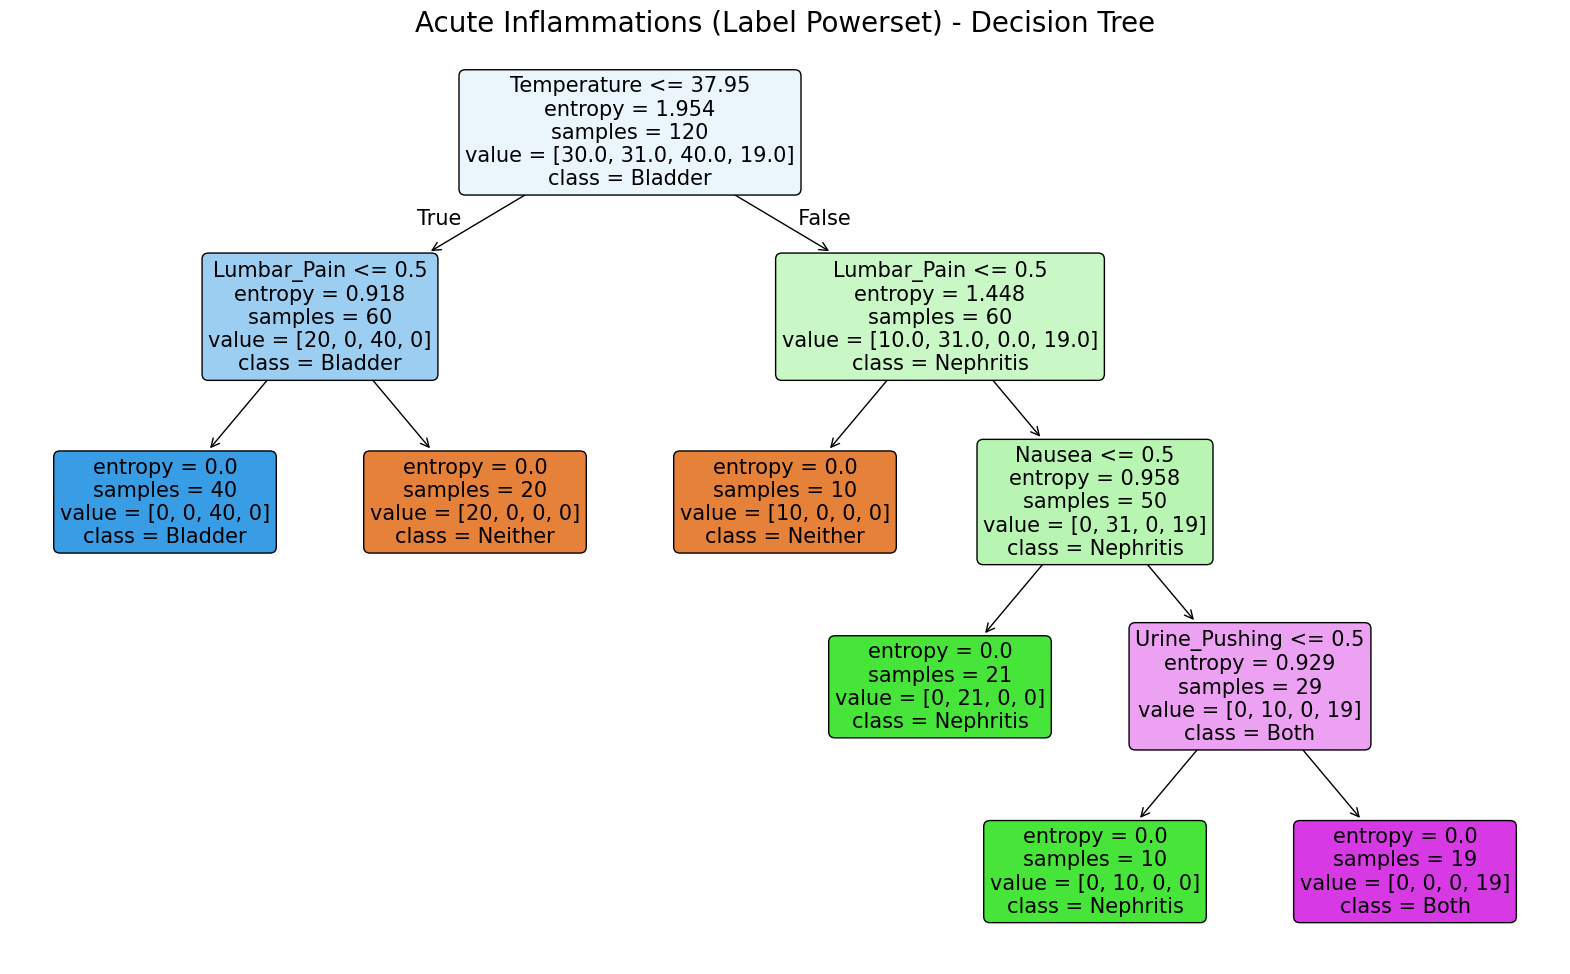

Tree depth: 4
Number of leaf nodes: 6
Classes: [0 1 2 3]


In [18]:
# Convert yes/no values to binary values (1/0)
binary_columns = column_names[1:]

acute_data[binary_columns] = acute_data[binary_columns].apply(
    lambda col: col.map({'yes': 1, 'no': 0})
).astype(int)

# Display the updated dataset
display(acute_data.head())

# Display the updated dataset
display(acute_data.head())

# Independent variables (6 patient features:'Temperature', 'Nausea', 'Lumbar_Pain','Urine_Pushing', 'Micturition_Pains', 'Burning_Urethra')
ind_vars = acute_data.iloc[:, :6]

# Dependent variables (2 diagnosis labels: 'Bladder_Inflammation', 'Nephritis')
dep_vars = acute_data.iloc[:, 6:]

print("Independent variables shape:", ind_vars.shape)
print("Target variables shape:", dep_vars.shape)

# Combine the two diagnosis labels into one multiclass target
multiclass_tar = dep_vars['Bladder_Inflammation'] * 2 + dep_vars['Nephritis']

# Display the distribution of the combined classes
print("Label Powerset Class Distribution:")
print(multiclass_tar.value_counts().sort_index())


############# Create a decision tree classifier #############
decision_tree = DecisionTreeClassifier(
    criterion='entropy',
    random_state=101
)

# Train the decision tree using the whole dataset
decision_tree.fit(ind_vars, multiclass_tar)


############## Plot the decision tree ############# 
plt.figure(figsize=(20, 12))

plot_tree(
    decision_tree,
    feature_names=ind_vars.columns,
    class_names=[
        ['Neither', 'Nephritis', 'Bladder', 'Both'][i]
        for i in decision_tree.classes_
    ],
    filled=True,
    rounded=True,
    fontsize=15
)

plt.title('Acute Inflammations (Label Powerset) - Decision Tree', fontsize=20)
plt.show()

# Display information about the decision tree
print("Tree depth:", decision_tree.get_depth())
print("Number of leaf nodes:", decision_tree.get_n_leaves())
print("Classes:", decision_tree.classes_)

### (c) Convert the decision rules

In [19]:
# Map the multiclass target values to diagnosis names
class_names = {
    0: 'Neither diagnosis',
    1: 'Nephritis only',
    2: 'Bladder inflammation only',
    3: 'Both diagnosis'
}

def extract_if_then_rules(model, feature_names):

    tree = model.tree_
    rules = []

    def traverse(node, conditions):

        # Check if the current node is a leaf
        if tree.feature[node] == _tree.TREE_UNDEFINED:

            # Determine the predicted class
            class_index = tree.value[node][0].argmax()
            predicted_class = int(model.classes_[class_index])

            # Create an IF-THEN statement
            rule = (
                "IF " + " AND ".join(conditions)
                + " THEN Class " + str(predicted_class)
                + " (" + class_names[predicted_class] + ")"
            )

            rules.append(rule)
            return

        # Get the splitting feature and threshold
        feature = feature_names[tree.feature[node]]
        threshold = tree.threshold[node]

        # Traverse the left branch
        traverse(
            tree.children_left[node],
            conditions + [f"{feature} <= {threshold:.2f}"]
        )

        # Traverse the right branch
        traverse(
            tree.children_right[node],
            conditions + [f"{feature} > {threshold:.2f}"]
        )

    # Start at the root node
    traverse(0, [])

    return rules


# Extract rules from the existing decision tree
if_then_rules = extract_if_then_rules(
    decision_tree,
    list(ind_vars.columns)
)

# Display all IF-THEN rules
for i, rule in enumerate(if_then_rules, start=1):
    print(f"Rule {i}: {rule}")

Rule 1: IF Temperature <= 37.95 AND Lumbar_Pain <= 0.50 THEN Class 2 (Bladder inflammation only)
Rule 2: IF Temperature <= 37.95 AND Lumbar_Pain > 0.50 THEN Class 0 (Neither diagnosis)
Rule 3: IF Temperature > 37.95 AND Lumbar_Pain <= 0.50 THEN Class 0 (Neither diagnosis)
Rule 4: IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea <= 0.50 THEN Class 1 (Nephritis only)
Rule 5: IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing <= 0.50 THEN Class 1 (Nephritis only)
Rule 6: IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing > 0.50 THEN Class 3 (Both diagnosis)


### (d) cost-complexity pruning

Selected alpha: 0


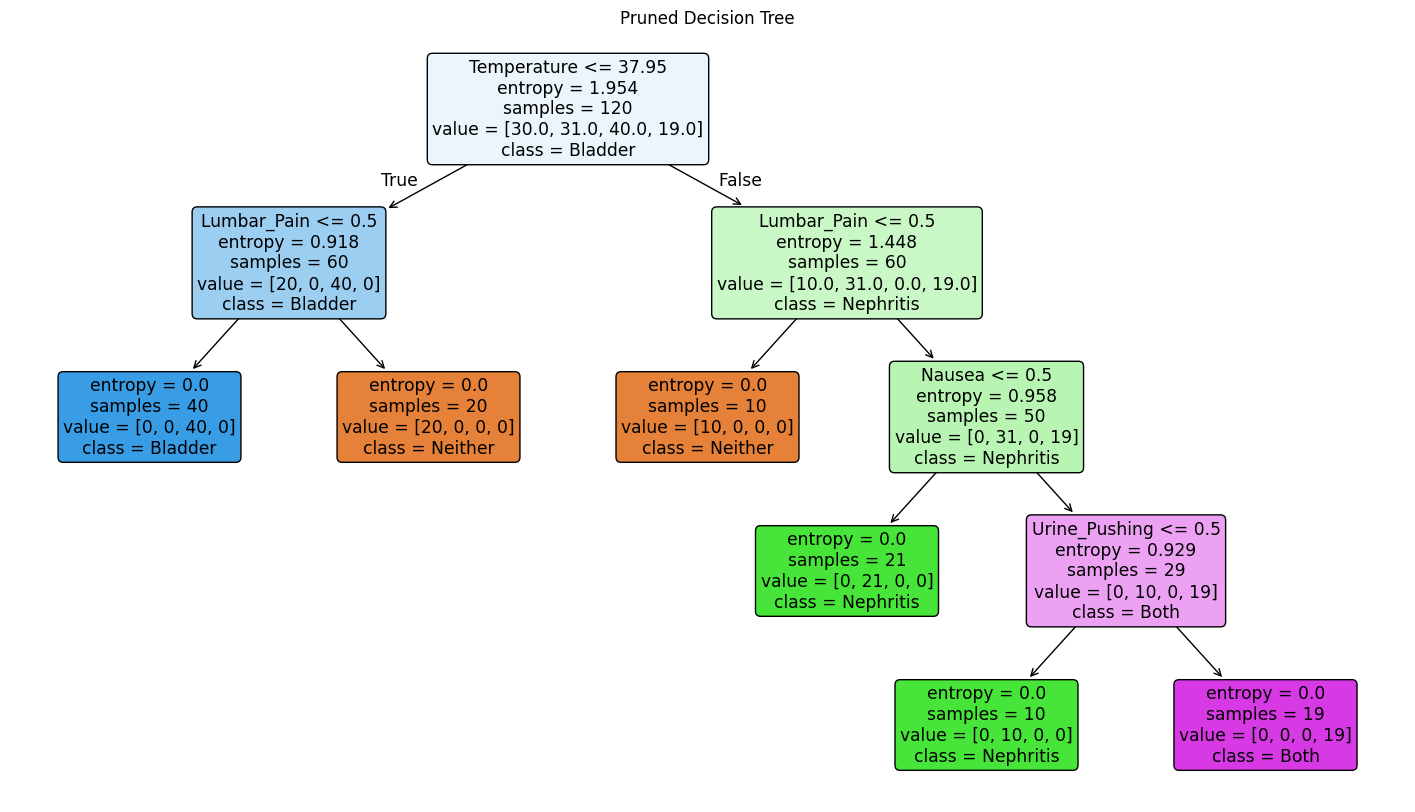

Rule 1: IF Temperature <= 37.95 AND Lumbar_Pain <= 0.50 THEN Class 2 (Bladder inflammation only)
Rule 2: IF Temperature <= 37.95 AND Lumbar_Pain > 0.50 THEN Class 0 (Neither diagnosis)
Rule 3: IF Temperature > 37.95 AND Lumbar_Pain <= 0.50 THEN Class 0 (Neither diagnosis)
Rule 4: IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea <= 0.50 THEN Class 1 (Nephritis only)
Rule 5: IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing <= 0.50 THEN Class 1 (Nephritis only)
Rule 6: IF Temperature > 37.95 AND Lumbar_Pain > 0.50 AND Nausea > 0.50 AND Urine_Pushing > 0.50 THEN Class 3 (Both diagnosis)


In [20]:
# Get possible cost-complexity pruning values
path = decision_tree.cost_complexity_pruning_path(
    ind_vars, multiclass_tar
)

# Original tree accuracy
original_accuracy = decision_tree.score(
    ind_vars, multiclass_tar
)

# Find the smallest tree that maintains original accuracy
best_alpha = 0
min_leaves = decision_tree.get_n_leaves()

for alpha in path.ccp_alphas:

    tree = DecisionTreeClassifier(
        criterion='entropy',
        random_state=101,
        ccp_alpha=alpha
    )

    tree.fit(ind_vars, multiclass_tar)

    if (tree.score(ind_vars, multiclass_tar) >= original_accuracy - 1e-10
            and tree.get_n_leaves() < min_leaves):

        best_alpha = alpha
        min_leaves = tree.get_n_leaves()

print("Selected alpha:", best_alpha)

# Train the pruned decision tree
pruned_tree = DecisionTreeClassifier(
    criterion='entropy',
    random_state=101,
    ccp_alpha=best_alpha
)

pruned_tree.fit(ind_vars, multiclass_tar)

# Plot the pruned tree
plt.figure(figsize=(18, 10))

plot_tree(
    pruned_tree,
    feature_names=ind_vars.columns,
    class_names=[
        ['Neither', 'Nephritis', 'Bladder', 'Both'][int(i)]
        for i in pruned_tree.classes_
    ],
    filled=True,
    rounded=True
)

plt.title("Pruned Decision Tree")
plt.show()

# Extract decision rules from the pruned tree
pruned_rules = extract_if_then_rules(
    pruned_tree,
    list(ind_vars.columns)
)

# Display the rules
for i, rule in enumerate(pruned_rules, start=1):
    print(f"Rule {i}: {rule}")

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [21]:
############ Directory setup for data files ############
NOTEBOOK_DIR = Path('.').resolve()

if NOTEBOOK_DIR.name.strip().lower() in ['notebook', 'notebooks']:
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    PROJECT_ROOT = NOTEBOOK_DIR

# Step up to the project root directory, then point to folder
DATA_DIR = PROJECT_ROOT / 'Communities_Crime' 

# Set the dataset file
DATA_FILE = DATA_DIR / 'communities.data.csv'

# Checks if the data directory exists
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Data directory not found at: {DATA_DIR}\n"
        "Check 'Communities_Crime' folder located in the project root folder."
    )

print(f"Project Root: {PROJECT_ROOT}")
print(f"Dataset Directory: {DATA_DIR}")
print(f"Dataset File: {DATA_FILE}")


############# Import communities.data.csv file ############ 
communities_data = pd.read_csv(
    DATA_FILE,
    header=None,
    na_values='?'
)

# Display the first five rows
display(communities_data.head())

# Display the dataset dimensions
print("Dataset shape:", communities_data.shape)

# Split the dataset into training (first 1495 rows) and test sets (remaining rows)
# Use the first 1495 rows for training
train_data = communities_data.iloc[:1495].copy()

# Use the remaining rows for testing
test_data = communities_data.iloc[1495:].copy()

# Verify the split
print("Training set shape:", train_data.shape)
print("Testing set shape:", test_data.shape)



Project Root: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 5 Data
Dataset Directory: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 5 Data/Communities_Crime
Dataset File: /Users/eliza/Desktop/DSCI 552 Machine Learning /F26/Homework Folder/Homework 5 Data/Communities_Crime/communities.data.csv


,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


Dataset shape: (1994, 128)
Training set shape: (1495, 128)
Testing set shape: (499, 128)


### (b) Missing values

In [22]:
############## Remove the five nonpredictive features #############
train_data = train_data.iloc[:, 5:].copy()
test_data = test_data.iloc[:, 5:].copy()

# Display updated dataset shapes
print("Training dataset shape:", train_data.shape)
print("Testing dataset shape:", test_data.shape)

############# Check for missing values ############# 

# Count missing values in the training set
train_missing = train_data.isnull().sum()

# Count missing values in the testing set
test_missing = test_data.isnull().sum()

# Display columns containing missing values
print("Training set missing values:")
print(train_missing[train_missing > 0])

print("\nTesting set missing values:")
print(test_missing[test_missing > 0])

# Display total missing values
print("\nTotal training missing values:", train_missing.sum())
print("Total testing missing values:", test_missing.sum())

############## Apply median imputation #############

# Separate independent variables and target variable
ind_train = train_data.iloc[:, :-1]
ind_test = test_data.iloc[:, :-1]

tar_train = train_data.iloc[:, -1]
tar_test = test_data.iloc[:, -1]

# Check total missing values after imputation 
print("Training target missing values:", tar_train.isnull().sum())
print("Testing target missing values:", tar_test.isnull().sum())

# Create a median imputer
imputer = SimpleImputer(strategy='median')

# Fit the imputer on training data
ind_train_imputed = pd.DataFrame(
    imputer.fit_transform(ind_train),
    columns=ind_train.columns,
    index=ind_train.index
)

# Apply the same imputer to testing data
ind_test_imputed = pd.DataFrame(
    imputer.transform(ind_test),
    columns=ind_test.columns,
    index=ind_test.index
)

############## Verify that missing values have been handled ############## 

# Check remaining missing values
print("Training missing values:",
      ind_train_imputed.isnull().sum().sum())

print("Testing missing values:",
      ind_test_imputed.isnull().sum().sum())

# Display final feature matrix shapes
print("Training features shape:", ind_train_imputed.shape)
print("Testing features shape:", ind_test_imputed.shape)




Training dataset shape: (1495, 123)
Testing dataset shape: (499, 123)
Training set missing values:
30        1
101    1256
102    1256
103    1256
104    1256
105    1256
106    1256
107    1256
108    1256
109    1256
110    1256
111    1256
112    1256
113    1256
114    1256
115    1256
116    1256
117    1256
121    1256
122    1256
123    1256
124    1256
126    1256
dtype: int64

Testing set missing values:
101    419
102    419
103    419
104    419
105    419
106    419
107    419
108    419
109    419
110    419
111    419
112    419
113    419
114    419
115    419
116    419
117    419
121    419
122    419
123    419
124    419
126    419
dtype: int64

Total training missing values: 27633
Total testing missing values: 9218
Training target missing values: 0
Testing target missing values: 0


Training missing values: 0
Testing missing values: 0
Training features shape: (1495, 122)
Testing features shape: (499, 122)


### (c) Plot a correlation matrix

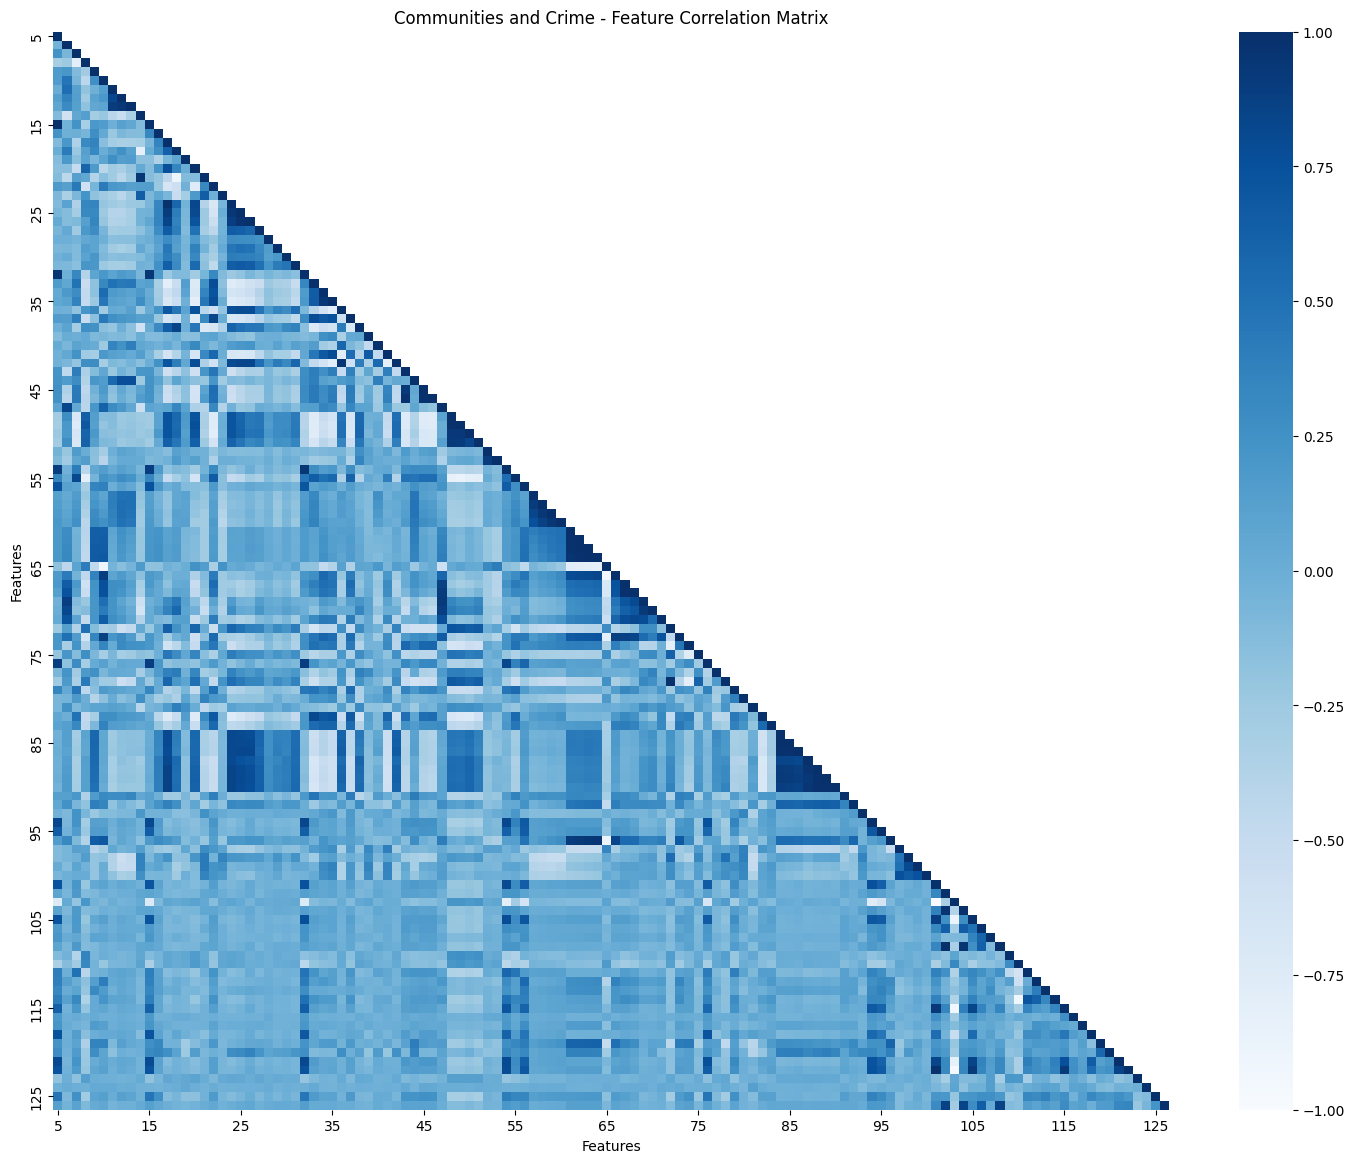

In [23]:
############## Plot correlation matrix for the features ############## 

# Calculate the correlation matrix
correlation_matrix = ind_train_imputed.corr()

# Create a cover for the upper triangle (only shows half the graph to prevent clutter)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

# Plot the correlation matrix
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap='Blues',
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=10,
    yticklabels=10
)

plt.xlabel('Features')
plt.ylabel('Features')
plt.title('Communities and Crime - Feature Correlation Matrix')
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [24]:
############## Calculate the Coefficient of Variation CV ############## 

# Calculate the sample mean for each feature
feature_means = ind_train_imputed.mean()

# Calculate the sample standard deviation for each feature
feature_stds = ind_train_imputed.std(ddof=1) # ddof=1 is sample std with (n-1) as denominator 

# Calculate the coefficient of variation (CV)
feature_cv = feature_stds / feature_means

# Display the results
cv_results = pd.DataFrame({
    'Mean': feature_means,
    'Standard Deviation': feature_stds,
    'CV': feature_cv
})

display(cv_results)

,Mean,Standard Deviation,CV
5,0.058167,0.130359,2.241105
6,0.461732,0.164284,0.355800
7,0.179839,0.256970,1.428885
8,0.752829,0.248594,0.330213
9,0.153712,0.208910,1.359100
...,...,...,...
122,0.038074,0.062650,1.645508
123,0.752495,0.084304,0.112032
124,0.492308,0.164974,0.335104
125,0.093304,0.238201,2.552946


### (e) Scatter plots and box plots for highest CV features

Top 11 Features with Highest CV:


113    5.527059
95     4.292923
94     3.470952
54     3.058964
56     2.926635
125    2.552946
32     2.342443
101    2.248042
5      2.241105
15     2.038461
76     1.968467
dtype: float64

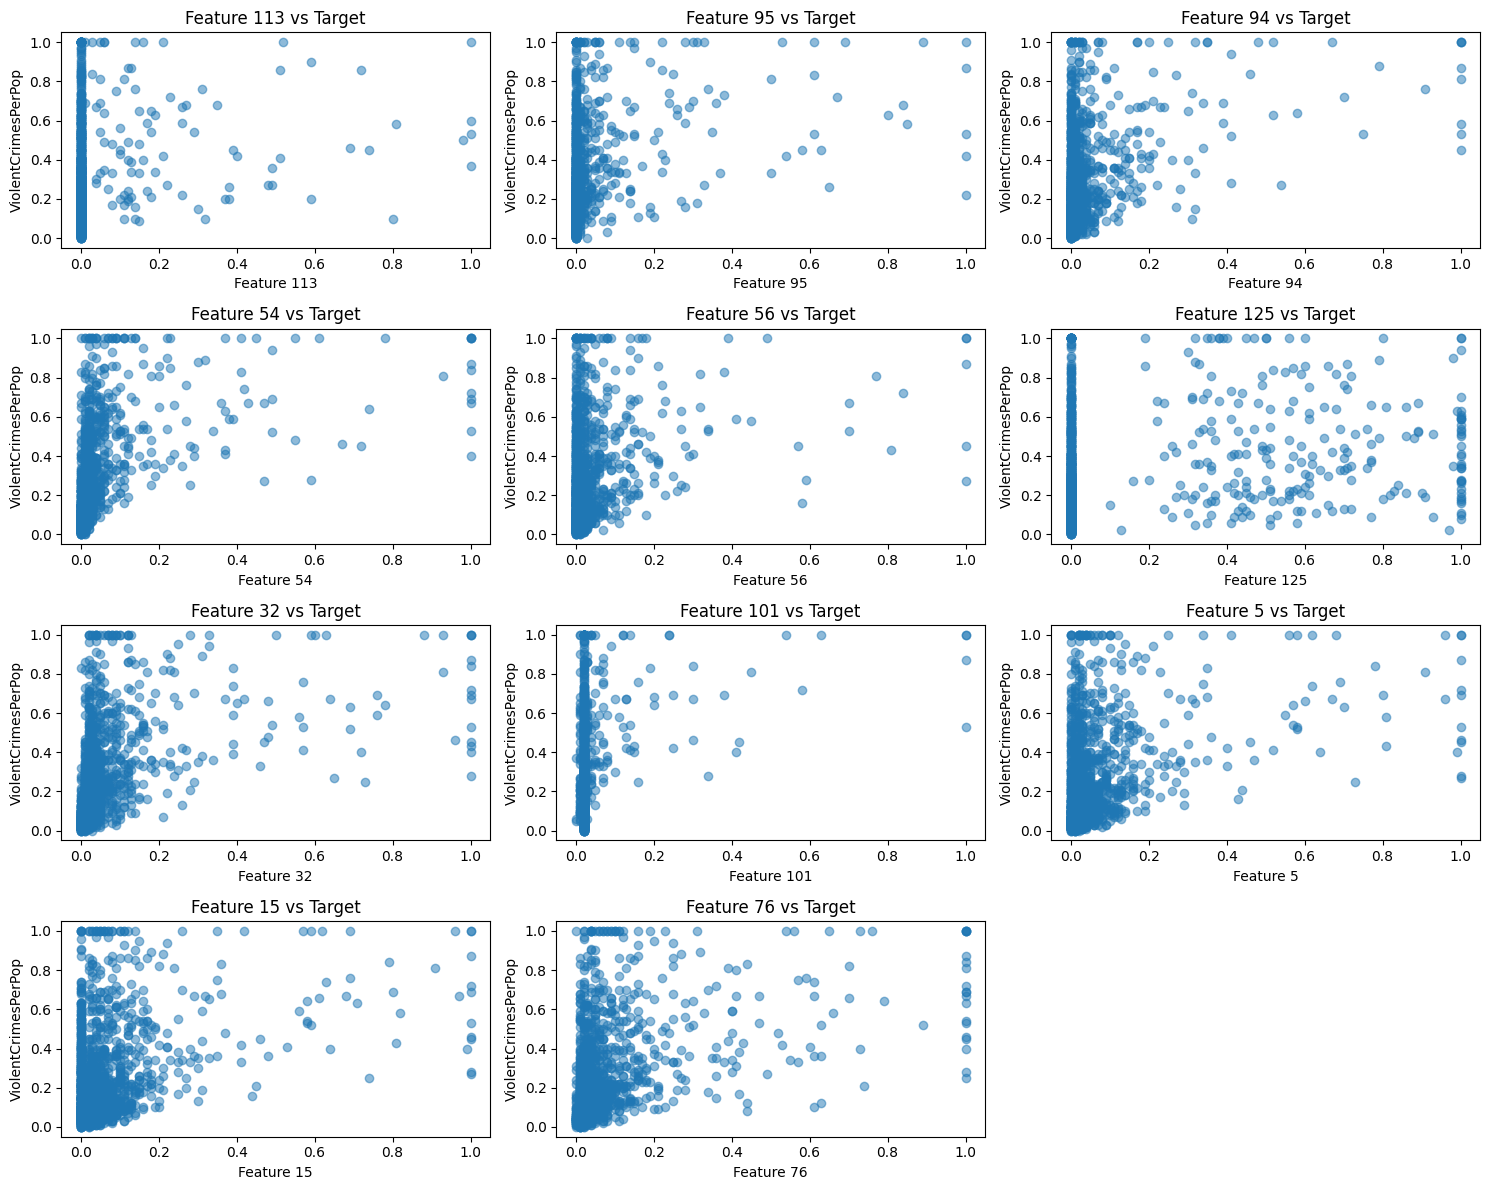

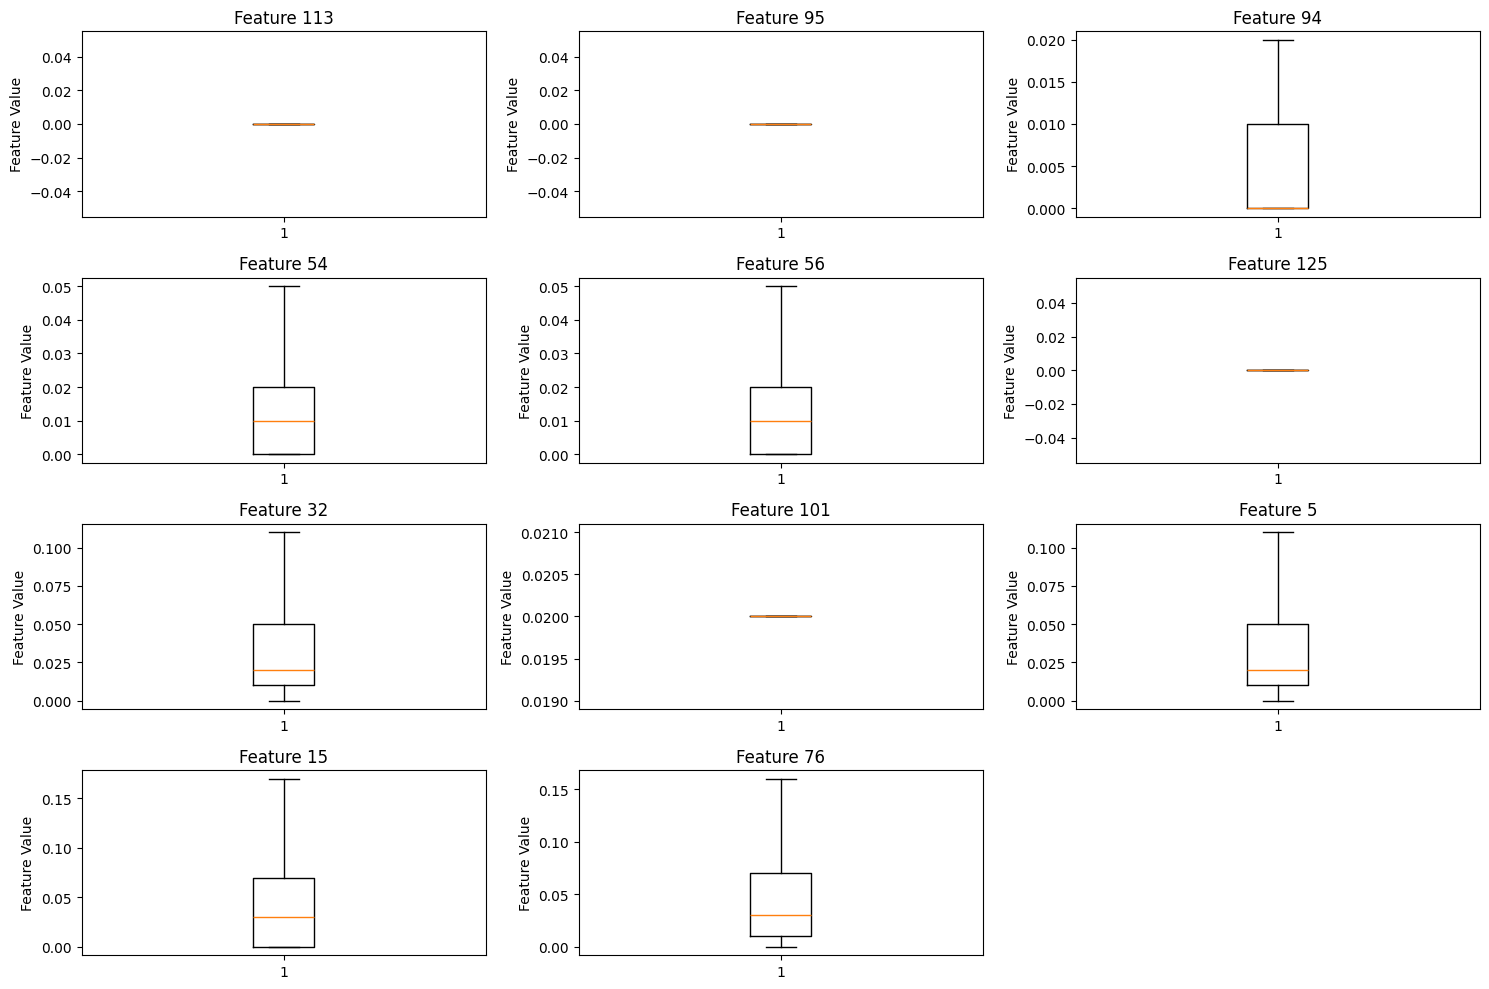

In [25]:
############### Calculate (⌊√128⌋ = 11) to determine number of features needed with highest CV ###############

# Select the 11 features with the highest CV
top_features = feature_cv.sort_values(ascending=False).head(11)

# Display the selected features and their CV values
print("Top 11 Features with Highest CV:")
display(top_features)

############### Scatter Plot ###############

# Create scatter plots for the top 11 features
plt.figure(figsize=(15, 12))

for i, feature in enumerate(top_features.index):

    plt.subplot(4, 3, i + 1)

    plt.scatter(
        ind_train_imputed[feature],
        tar_train,
        alpha=0.5
    )

    plt.xlabel(f'Feature {feature}')
    plt.ylabel('ViolentCrimesPerPop')
    plt.title(f'Feature {feature} vs Target')

plt.tight_layout()
plt.show()

############### Box Plot ###############

# Create box plots for the top 11 features
plt.figure(figsize=(15, 10))

for i, feature in enumerate(top_features.index):

    plt.subplot(4, 3, i + 1)

    plt.boxplot(
        ind_train_imputed[feature].dropna(),
        showfliers=False
    )

    plt.title(f'Feature {feature}')
    plt.ylabel('Feature Value')

plt.tight_layout()
plt.show()



## (e) Scatter Plots Anlysis

Scatter Plot significance: 
No conclusions about the statistical significance can be determined. The scatter plots display the relationship between the 11 features with highest CV and target variables. It does not show any significance of those features as more advanced tests needs to conducted. 

### (f) Fit a linear model

In [26]:
###############  Fit linear model using least squares to training set and report test error ###############

# Create a linear regression model using least squares
linear_model = LinearRegression()

# Fit the model using the training set
linear_model.fit(ind_train_imputed, tar_train)

# Predict target variable (ViolentCrimesPerPop) using the testing set
tar_pred = linear_model.predict(ind_test_imputed)

# Calculate the test Mean Squared Error (MSE)
test_mse = mean_squared_error(tar_test, tar_pred)

# Display test error
print("Linear Regression Test MSE:", test_mse)

Linear Regression Test MSE: 0.017966215426067335


### (g) Fit a ridge regression model

In [27]:
############### Fit ridge regression model on training set, with λ chosen by cross-validation ############### 


# Define candidate lambda values
lambda_values = np.logspace(-4, 4, 100)

# Create a Ridge Regression model with cross-validation
ridge_model = make_pipeline(
    StandardScaler(),
    RidgeCV(
        alphas=lambda_values,
        cv=5,
        scoring='neg_mean_squared_error'
    )
)

# Fit the model using the training set
ridge_model.fit(ind_train_imputed, tar_train)

# Retrieve the selected lambda
best_lambda = ridge_model.named_steps['ridgecv'].alpha_

print("Best lambda:", best_lambda)

############### Predict and calculate the test error ############### 

# Predict target values using the testing set
ridge_tar_pred = ridge_model.predict(ind_test_imputed)

# Calculate the Ridge Regression test MSE
ridge_test_mse = mean_squared_error(tar_test, ridge_tar_pred)

# Display the results
print("Selected lambda:", best_lambda)
print("Ridge Regression Test MSE:", ridge_test_mse)


Best lambda: 79.24828983539186
Selected lambda: 79.24828983539186
Ridge Regression Test MSE: 0.017431130507402384


### (h) Fit a LASSO model

In [28]:
############### LASSO with existing imputed features ###############

# Define candidate lambda values
lambda_values = np.logspace(-4, 1, 100)

# Create a LASSO model with 5-fold cross-validation
lasso_model = LassoCV(
    alphas=lambda_values,
    cv=5,
    max_iter=100000,
    random_state=101
)

# Fit the model using the training set
lasso_model.fit(ind_train_imputed, tar_train)

# Predict the target values using the testing set
lasso_tar_pred = lasso_model.predict(ind_test_imputed)

# Calculate the test error
lasso_test_mse = mean_squared_error(tar_test, lasso_tar_pred)

# Display results
print("Unstandarized LASSO lambda:", lasso_model.alpha_)
print("Unstandarized LASSO Test MSE:", lasso_test_mse)


############### Identify the variables selected by LASSO ###############

# Identify variables with nonzero coefficients
selected_features = ind_train_imputed.columns[
    ~np.isclose(lasso_model.coef_, 0, atol=1e-8)
]

# Display selected features
print("Variables Selected by LASSO:")
print(list(selected_features))

print("Number of selected variables:", len(selected_features))


############### LASSO with standardized features ###############

# Create LASSO model with standardized features
lasso_standardized = make_pipeline(
    StandardScaler(),
    LassoCV(
        alphas=lambda_values,
        cv=5,
        max_iter=100000,
        random_state=101
    )
)

# Fit the standardized LASSO model
lasso_standardized.fit(ind_train_imputed, tar_train)

# Predict the testing target values
lasso_std_tar_pred = lasso_standardized.predict(ind_test_imputed)

# Calculate test MSE
lasso_std_test_mse = mean_squared_error(
    tar_test,
    lasso_std_tar_pred
)

# Retrieve selected lambda
lasso_std_lambda = lasso_standardized.named_steps['lassocv'].alpha_

print("Standardized LASSO lambda:", lasso_std_lambda)
print("Standardized LASSO Test MSE:", lasso_std_test_mse)


############### Identify selected variables from standardized LASSO ###############

# Retrieve the fitted standardized LASSO model
standardized_model = lasso_standardized.named_steps['lassocv']

# Identify selected variables
selected_std_features = ind_train_imputed.columns[
    ~np.isclose(standardized_model.coef_, 0, atol=1e-8)
]

print("Variables Selected by Standardized LASSO:")
print(list(selected_std_features))

print("Number of selected variables:", len(selected_std_features))


############### Compare the test errors ############### 

# Compare LASSO models
lasso_comparison = pd.DataFrame({
    'Model': [
        'LASSO (Unstandarized Features)',
        'LASSO (Standardized Features)'
    ],
    'Selected Lambda': [
        lasso_model.alpha_,
        lasso_std_lambda
    ],
    'Test MSE': [
        lasso_test_mse,
        lasso_std_test_mse
    ],
    'Selected Features': [
        len(selected_features),
        len(selected_std_features)
    ]
})

display(lasso_comparison)

Unstandarized LASSO lambda: 0.0001261856883066021
Unstandarized LASSO Test MSE: 0.017615034821046874
Variables Selected by LASSO:
[7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 107, 109, 111, 112, 113, 116, 117, 118, 119, 120, 121, 123, 124]
Number of selected variables: 74
Standardized LASSO lambda: 0.0008111308307896872
Standardized LASSO Test MSE: 0.017670233667342734
Variables Selected by Standardized LASSO:
[7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]
Number of selected variables: 72


,Model,Selected Lambda,Test MSE,Selected Features
0,LASSO (Unstandarized Features),0.000126,0.017615,74
1,LASSO (Standardized Features),0.000811,0.017670,72


(h) Unstandarized LASSO model vs Standarized LASSO model Analysis

The Test MSE value for the LASSO (Unstandarized Features) is 0.017615 and Test MSE value for the LASSO (standarized Features) is 0.017670. The lower Test MSE value from the Unstandarized LASSO indicates a more efficient predictive performance on the testing set. The difference is only by 0.000055 which is an extremely small difference. The results suggest the standardization did not improve the performance of LASSO regression. 

### (i) Fit a PCR model

In [29]:
############### Fit PCR with cross-validation ############### 

# Create a PCR pipeline
pcr_pipeline = Pipeline([
    ('pca', PCA()),
    ('linear', LinearRegression())
])

# Define possible numbers of principal components
component_values = np.arange(1, ind_train_imputed.shape[1] + 1)

# Use cross-validation to select the best number of components
pcr_model = GridSearchCV(
    pcr_pipeline,
    param_grid={'pca__n_components': component_values},
    cv=5,
    scoring='neg_mean_squared_error'
)

# Fit the PCR model using the training set
pcr_model.fit(ind_train_imputed, tar_train)

# Display the selected number of components
best_M = pcr_model.best_params_['pca__n_components']

print("Best number of principal components (M):", best_M)


############### Predict and calculate the test error ###############

# Predict target values using the testing set
pcr_tar_pred = pcr_model.predict(ind_test_imputed)

# Calculate test Mean Squared Error
pcr_test_mse = mean_squared_error(tar_test, pcr_tar_pred)

# Display results
print("Selected M:", best_M)
print("PCR Test MSE:", pcr_test_mse)

Best number of principal components (M): 96
Selected M: 96
PCR Test MSE: 0.01833986173208233


### (j) Fit a boosting tree

In [30]:
############### L1-Penalized Gradient Boosting Trees ############### 

# Define candidate alpha values for L1 regularization
alpha_values = np.logspace(-4, 1, 20)

# Create the XGBoost regression model
xgb_model = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=101,
    n_jobs=1
)

# Use 5-fold cross-validation to select alpha
xgb_cv = GridSearchCV(
    estimator=xgb_model,
    param_grid={'reg_alpha': alpha_values},
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

# Fit the model using the training set
xgb_cv.fit(ind_train_imputed, tar_train)

# Retrieve the best alpha
best_alpha = xgb_cv.best_params_['reg_alpha']

# Predict the target values using the testing set
xgb_tar_pred = xgb_cv.predict(ind_test_imputed)

# Calculate the test MSE
xgb_test_mse = mean_squared_error(tar_test, xgb_tar_pred)

# Display results
print("Selected alpha:", best_alpha)
print("XGBoost Test MSE:", xgb_test_mse)

Selected alpha: 0.0069519279617756054
XGBoost Test MSE: 0.016128027956754627
